# Workbook Mandiri — Pembersihan dan Analisis Kualitas Data Transaksi Koperasi 2025
**Nama* Aqila Diliansyah Putra
Nim: 0110225025
**Mata kuliah:** Exploratory Data Analysis (KMTI21133)  
**Dataset:** `transaksi_koperasi_2025.csv`  
**Cakupan data:** transaksi koperasi, Agustus–November 2025

Notebook ini menggabungkan proses diagnosis, pembersihan, dokumentasi keputusan, pemeriksaan ulang, eksplorasi, dan ekspor hasil. Data mentah tidak ditimpa. Semua perubahan dilakukan pada salinan.

**Catatan akademik:** notebook ini disusun sebagai pengerjaan yang dapat ditinjau dan dijelaskan. Peta kategori dan aturan penyatuan ID adalah asumsi kerja yang harus dikonfirmasi kepada pengelola data/dosen. Hasil pemeriksaan kemiripan tidak dapat dijamin; pastikan kamu memahami dan dapat mempertanggungjawabkan keputusan yang digunakan.

## Daftar isi

1. Persiapan dan pemuatan dataset
2. Diagnosis awal dan profil kualitas
3. Prinsip serta urutan pembersihan
4. Pipeline pembersihan yang dapat diulang
5. Pemeriksaan setiap keputusan
6. Penanganan nilai kosong dan nilai tidak valid
7. Kolom turunan dan pengelompokan nilai transaksi
8. Analisis eksploratif
9. Bentuk tabel tidy: pivot, melt, dan merge
10. Perbandingan sebelum–sesudah
11. Uji reproduktibilitas
12. Ekspor CSV, cleaning log, dan laporan PDF
13. Daftar periksa sebelum pengumpulan

Jalankan notebook dari atas ke bawah dengan **Runtime → Restart session and run all**.

## 1. Persiapan dan pemuatan dataset

Unggah file CSV transaksi yang diberikan. Notebook menerima nama file apa pun yang dipilih, lalu menyimpan nama file tersebut sebagai sumber data untuk proses ini.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re, os, json, textwrap
from pathlib import Path
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

NAMA_FILE = "transaksi_koperasi_2025.csv"

if not Path(NAMA_FILE).exists():
    try:
        from google.colab import files
        unggahan = files.upload()
        if not unggahan:
            raise ValueError("Belum ada file yang diunggah.")
        NAMA_FILE = next(iter(unggahan))
    except ImportError:
        raise FileNotFoundError(
            f"{NAMA_FILE} tidak ditemukan. Letakkan CSV di folder kerja notebook."
        )

mentah = pd.read_csv(NAMA_FILE)
print("Sumber:", NAMA_FILE)
print(f"Ukuran data mentah: {mentah.shape[0]:,} baris × {mentah.shape[1]} kolom")
display(mentah.head())

Saving transaksi_koperasi_2025_bersih.csv to transaksi_koperasi_2025_bersih.csv
Sumber: transaksi_koperasi_2025_bersih.csv
Ukuran data mentah: 1,493 baris × 26 kolom


,id_transaksi,tanggal_transaksi,id_anggota,nama_produk,kategori,satuan,jumlah,harga_satuan,diskon_persen,total_bayar,metode_bayar,kasir,saldo_simpanan,berat_kg,rating_layanan,catatan_kasir,total_seharusnya,selisih_total,total_mencurigakan,berlaku_berat,ada_catatan,bulan,hari,jam,nilai_bersih,kelas_nilai
0,TRX250665,2025-08-27 09:43:00,AGT1014,Map Plastik,ATK,pcs,5.00,4000,0.00,20000,Tunai,Dimas,"45,000.00",1.72,5.00,Minta struk,"20,000.00",0.00,False,True,True,2025-08,Wednesday,9,20000,Kecil
1,TRX251255,2025-10-09 16:57:00,AGT1148,Map Plastik,ATK,pcs,NaN,4000,0.00,12000,NaN,Bagus,"159,000.00",3.59,5.00,Minta struk,NaN,NaN,NaN,True,True,2025-10,Thursday,16,12000,Kecil
2,TRX250482,2025-08-27 09:20:00,AGT1102,Gorengan 5pcs,Makanan,porsi,4.00,6000,0.00,24000,Tunai,Bagus,NaN,2.01,NaN,Minta struk,"24,000.00",0.00,False,True,True,2025-08,Wednesday,9,24000,Kecil
3,TRX250414,2025-10-30 07:58:00,AGT1081,Pulpen Hitam,ATK,pcs,6.00,3500,0.00,21000,QRIS,Rina,NaN,3.60,5.00,Minta struk,"21,000.00",0.00,False,True,True,2025-10,Thursday,7,21000,Kecil
4,TRX250097,2025-09-06 17:47:00,AGT1053,Air Mineral 600ml,Minuman,botol,8.00,4000,0.00,32000,Tunai,Rina,"35,000.00",3.43,4.00,Minta struk,"32,000.00",0.00,False,True,True,2025-09,Saturday,17,32000,Sedang


## 2. Diagnosis awal

Pemeriksaan awal mencakup struktur, tipe data, nilai kosong, duplikasi penuh, nilai unik, dan ringkasan numerik. Tahap ini hanya membaca data; belum ada baris atau kolom yang diubah.

In [2]:
print("=== STRUKTUR ===")
print("Baris:", len(mentah), "| Kolom:", len(mentah.columns))
display(mentah.dtypes.rename("tipe_data").to_frame())

print("=== NILAI KOSONG ===")
profil_awal = pd.DataFrame({
    "kosong": mentah.isna().sum(),
    "persen_kosong": (mentah.isna().mean() * 100).round(2),
    "nilai_unik": mentah.nunique(dropna=True)
}).sort_values("persen_kosong", ascending=False)
display(profil_awal)

print("Duplikat baris penuh:", int(mentah.duplicated().sum()))
print("ID transaksi kosong:", int(mentah["id_transaksi"].isna().sum()))
print("ID transaksi berulang (baris):",
      int(mentah["id_transaksi"].duplicated(keep=False).sum()))
display(mentah.describe(include="all").T)

=== STRUKTUR ===
Baris: 1493 | Kolom: 26


,tipe_data
id_transaksi,object
tanggal_transaksi,object
id_anggota,object
nama_produk,object
kategori,object
satuan,object
jumlah,float64
harga_satuan,int64
diskon_persen,float64
total_bayar,int64


=== NILAI KOSONG ===


,kosong,persen_kosong,nilai_unik
catatan_kasir,1004,67.25,4
berat_kg,341,22.84,976
saldo_simpanan,156,10.45,624
rating_layanan,46,3.08,4
selisih_total,36,2.41,42
total_seharusnya,36,2.41,130
total_mencurigakan,36,2.41,2
jumlah,29,1.94,8
metode_bayar,28,1.88,4
diskon_persen,9,0.60,3


Duplikat baris penuh: 0
ID transaksi kosong: 0
ID transaksi berulang (baris): 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_transaksi,1493,1493,TRX250665,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tanggal_transaksi,1493,1488,2025-11-14 11:21:00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id_anggota,1493,259,AGT1041,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nama_produk,1493,18,Roti Isi,138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kategori,1493,5,Makanan,488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
satuan,1493,5,porsi,488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jumlah,"1,464.00",NaN,NaN,NaN,4.25,2.40,1.00,2.00,4.00,6.00,8.00
harga_satuan,"1,493.00",NaN,NaN,NaN,"7,834.23","6,482.25",500.00,"4,000.00","6,000.00","8,000.00","35,000.00"
diskon_persen,"1,484.00",NaN,NaN,NaN,0.81,2.37,0.00,0.00,0.00,0.00,10.00
total_bayar,"1,493.00",NaN,NaN,NaN,"32,916.83","47,456.41",250.00,"12,000.00","24,000.00","40,000.00","800,000.00"


## 3. Prinsip dan urutan pembersihan

Urutan diterapkan agar satu jenis masalah tidak menyembunyikan masalah lain:

1. Konversi tipe data numerik dan tanggal.
2. Rapikan spasi pada kolom teks.
3. Ubah placeholder menjadi nilai kosong.
4. Seragamkan kategori berdasarkan peta keputusan.
5. Tangani duplikasi penuh, ID berulang, dan ID kosong.
6. Tandai atau kosongkan nilai yang tidak valid.
7. Evaluasi nilai kosong tanpa imputasi otomatis.
8. Buat kolom turunan untuk analisis.

**Prinsip penting:** jangan menebak nilai pengganti. Jika sumber kebenaran tidak tersedia, tandai masalah dan jelaskan keterbatasannya.

## 4. Pipeline pembersihan yang dapat diulang

Fungsi `bersihkan()` menerima DataFrame mentah dan menghasilkan DataFrame olahan serta cleaning log. Fungsi membuat salinan sehingga objek `mentah` tetap utuh.

In [3]:
def bersihkan(df_mentah):
    x = df_mentah.copy(deep=True)
    jejak = []

    def catat(langkah, terdampak, alasan):
        jejak.append({
            "Langkah": langkah,
            "Baris terdampak": int(terdampak),
            "Alasan": alasan
        })

    # LANGKAH 1 — konversi total pembayaran ke numerik.
    berformat_rp = x["total_bayar"].astype("string").str.startswith("Rp", na=False)
    x["total_bayar"] = pd.to_numeric(
        x["total_bayar"].astype("string")
         .str.replace("Rp", "", regex=False)
         .str.replace(".", "", regex=False)
         .str.strip(),
        errors="coerce"
    )
    catat(
        "Konversi total_bayar ke angka",
        berformat_rp.sum(),
        'Menghapus simbol "Rp" dan titik pemisah ribuan agar nominal dapat dihitung.'
    )

    # LANGKAH 2 — parsing tanggal ISO dan DD/MM/YYYY secara terpisah.
    t = x["tanggal_transaksi"].astype("string")
    pola_iso = t.str.match(r"^\d{4}-", na=False)
    tanggal_baru = pd.Series(pd.NaT, index=x.index, dtype="datetime64[ns]")
    tanggal_baru.loc[pola_iso] = pd.to_datetime(
        t.loc[pola_iso], format="%Y-%m-%d %H:%M:%S", errors="coerce"
    )
    tanggal_baru.loc[~pola_iso] = pd.to_datetime(
        t.loc[~pola_iso], format="%d/%m/%Y %H:%M", errors="coerce"
    )
    gagal_tanggal = int(tanggal_baru.isna().sum())
    x["tanggal_transaksi"] = tanggal_baru
    catat(
        "Konversi tanggal berdasarkan pola format",
        len(x),
        "Tanggal ISO dan DD/MM/YYYY diparse terpisah agar interpretasi hari-bulan tidak merusak tanggal ISO."
    )

    # LANGKAH 3 — rapikan spasi di seluruh kolom teks.
    kolom_teks = x.select_dtypes(include=["object", "string"]).columns.tolist()
    jumlah_spasi = 0
    for kolom in kolom_teks:
        s = x[kolom].astype("string")
        jumlah_spasi += int((s != s.str.strip()).sum())
        x[kolom] = s.str.strip()
    catat(
        "Buang spasi awal dan akhir kolom teks",
        jumlah_spasi,
        "Spasi tersembunyi dapat membuat kategori atau identitas yang sama terbaca sebagai nilai berbeda."
    )

    # LANGKAH 4 — placeholder teks menjadi kosong.
    placeholder = ["n/a", "na", "-", "", "null", "none",
                   "tidak diketahui", "unknown", "?", "#n/a"]
    jumlah_placeholder = 0
    for kolom in kolom_teks:
        s = x[kolom].astype("string")
        mask = s.str.lower().isin(placeholder)
        jumlah_placeholder += int(mask.sum())
        x.loc[mask, kolom] = pd.NA
    catat(
        "Placeholder teks menjadi kosong",
        jumlah_placeholder,
        "Placeholder bukan observasi bermakna; menjadikannya kosong mencegah kategori palsu."
    )

    # LANGKAH 5 — placeholder rating.
    jumlah_999 = int((x["rating_layanan"] == -999).sum())
    x.loc[x["rating_layanan"] == -999, "rating_layanan"] = np.nan
    catat(
        "Placeholder -999 pada rating menjadi kosong",
        jumlah_999,
        "-999 berada di luar skala rating layanan dan akan merusak statistik ringkasan."
    )

    # LANGKAH 6 — normalisasi kategori dan peta keputusan manual.
    x["kategori"] = x["kategori"].astype("string").str.strip().str.title()
    peta_kategori = {
        "Atk": "ATK",
        "Alat Tulis": "ATK",
        "Minumam": "Minuman"
    }
    kategori_sebelum = x["kategori"].nunique(dropna=True)
    x["kategori"] = x["kategori"].replace(peta_kategori)
    kategori_sesudah = x["kategori"].nunique(dropna=True)
    catat(
        "Seragamkan kategori",
        kategori_sebelum - kategori_sesudah,
        "Kapitalisasi dinormalkan; sinonim/salah ketik dipetakan eksplisit. Konfirmasi pemetaan dengan pengelola data."
    )
    x["metode_bayar"] = (
        x["metode_bayar"].astype("string").str.strip().str.title()
          .replace({"Qris": "QRIS"})
    )
    x["kasir"] = x["kasir"].astype("string").str.strip().str.title()

    # LANGKAH 7 — hapus duplikat penuh setelah normalisasi teks.
    n_duplikat = int(x.duplicated().sum())
    x = x.drop_duplicates()
    catat(
        "Hapus duplikat persis",
        n_duplikat,
        "Seluruh kolom identik setelah normalisasi; satu salinan dipertahankan."
    )

    # LANGKAH 8 — satukan ID transaksi yang berulang.
    n_id_berulang = int(x["id_transaksi"].duplicated(keep=False).sum())
    x = (
        x.sort_values("catatan_kasir", na_position="last")
         .drop_duplicates(subset=["id_transaksi"], keep="first")
    )
    catat(
        "Satukan duplikat menurut id_transaksi",
        n_id_berulang,
        "Satu ID diasumsikan mewakili satu transaksi; baris dengan catatan terisi diprioritaskan."
    )

    # LANGKAH 9 — buang baris yang tidak memiliki primary key.
    n_id_kosong = int(x["id_transaksi"].isna().sum())
    x = x[x["id_transaksi"].notna()].copy()
    catat(
        "Buang baris tanpa id_transaksi",
        n_id_kosong,
        "Tanpa kunci transaksi, baris tidak dapat ditelusuri secara andal."
    )

    # LANGKAH 10 — nilai jumlah nol/negatif dikosongkan, baris dipertahankan.
    n_jumlah = int((x["jumlah"] <= 0).sum())
    x.loc[x["jumlah"] <= 0, "jumlah"] = np.nan
    catat(
        "jumlah <= 0 menjadi kosong",
        n_jumlah,
        "Belum dapat dipastikan apakah retur atau salah input; nilai dikosongkan tetapi baris dipertahankan."
    )

    # LANGKAH 11 — diskon di luar rentang 0–100 dikosongkan.
    mask_diskon = (x["diskon_persen"] < 0) | (x["diskon_persen"] > 100)
    n_diskon = int(mask_diskon.sum())
    x.loc[mask_diskon, "diskon_persen"] = np.nan
    catat(
        "Diskon di luar 0–100 menjadi kosong",
        n_diskon,
        "Nilai di luar rentang persentase tidak valid; perlu konfirmasi pengurus sebelum koreksi."
    )

    # LANGKAH 12 — hitung ekspektasi dan tandai selisih, jangan timpa nominal.
    x["total_seharusnya"] = (
        x["jumlah"] * x["harga_satuan"] *
        (1 - x["diskon_persen"] / 100)
    ).round()
    x["selisih_total"] = x["total_bayar"] - x["total_seharusnya"]
    x["total_mencurigakan"] = x["selisih_total"].abs() > 1
    n_total_selisih = int(x["total_mencurigakan"].sum())
    catat(
        "Tandai total yang tidak cocok",
        n_total_selisih,
        "Tidak ditimpa karena belum diketahui apakah jumlah, harga, diskon, atau total bayar yang keliru."
    )

    # LANGKAH 13–15 — pertahankan missingness yang bermakna dan buat indikator.
    catat(
        "saldo_simpanan dibiarkan kosong",
        x["saldo_simpanan"].isna().sum(),
        "Pola diduga MNAR; imputasi dapat membiaskan rata-rata sehingga nilai kosong dilaporkan."
    )
    x["berlaku_berat"] = ~x["kategori"].isin(["Pulsa", "Jasa"])
    catat(
        "Tandai keberlakuan berat_kg",
        (~x["berlaku_berat"]).sum(),
        "Berat tidak relevan untuk pulsa/jasa; kekosongan struktural tidak diimputasi."
    )
    x["ada_catatan"] = x["catatan_kasir"].notna()
    catat(
        "Tandai keberadaan catatan kasir",
        (~x["ada_catatan"]).sum(),
        "Ketiadaan catatan merupakan informasi tentang pencatatan, bukan alasan mengisi teks buatan."
    )

    # LANGKAH 16 — kolom turunan untuk analisis.
    x = x.reset_index(drop=True)
    x["bulan"] = x["tanggal_transaksi"].dt.to_period("M").astype("string")
    x["hari"] = x["tanggal_transaksi"].dt.day_name()
    x["jam"] = x["tanggal_transaksi"].dt.hour
    x["nilai_bersih"] = x["total_bayar"]
    x["kelas_nilai"] = pd.cut(
        x["total_bayar"],
        bins=[0, 10_000, 30_000, 75_000, np.inf],
        labels=["Sangat kecil", "Kecil", "Sedang", "Besar"]
    )
    urutan = ["Sangat kecil", "Kecil", "Sedang", "Besar"]
    x["kelas_nilai"] = pd.Categorical(
        x["kelas_nilai"], categories=urutan, ordered=True
    )

    return x, pd.DataFrame(jejak), gagal_tanggal

data_bersih, log_df, gagal_tanggal = bersihkan(mentah)
print("Pipeline selesai.")
print("Data mentah:", mentah.shape, "| Data hasil:", data_bersih.shape)
print("Tanggal gagal diparse:", gagal_tanggal)
display(log_df)

Pipeline selesai.
Data mentah: (1493, 26) | Data hasil: (1493, 26)
Tanggal gagal diparse: 0


,Langkah,Baris terdampak,Alasan
0,Konversi total_bayar ke angka,0,"Menghapus simbol ""Rp"" dan titik pemisah ribuan..."
1,Konversi tanggal berdasarkan pola format,1493,Tanggal ISO dan DD/MM/YYYY diparse terpisah ag...
2,Buang spasi awal dan akhir kolom teks,0,Spasi tersembunyi dapat membuat kategori atau ...
3,Placeholder teks menjadi kosong,0,Placeholder bukan observasi bermakna; menjadik...
4,Placeholder -999 pada rating menjadi kosong,0,-999 berada di luar skala rating layanan dan a...
5,Seragamkan kategori,0,Kapitalisasi dinormalkan; sinonim/salah ketik ...
6,Hapus duplikat persis,0,Seluruh kolom identik setelah normalisasi; sat...
7,Satukan duplikat menurut id_transaksi,0,Satu ID diasumsikan mewakili satu transaksi; b...
8,Buang baris tanpa id_transaksi,0,"Tanpa kunci transaksi, baris tidak dapat ditel..."
9,jumlah <= 0 menjadi kosong,0,Belum dapat dipastikan apakah retur atau salah...


## 5. Memeriksa hasil setiap keputusan

### 5.1 Peta kategori

Peta ini harus transparan. `Minumam` dianggap salah ketik dari `Minuman`; `Alat Tulis` disatukan ke `ATK` sebagai asumsi sinonim. Jika pengelola data menggunakan definisi kategori berbeda, ubah peta dan jalankan ulang pipeline.

In [4]:
peta_keputusan = pd.DataFrame([
    ["Atk", "ATK", "Perbedaan kapitalisasi singkatan."],
    ["Alat Tulis", "ATK", "Asumsi sinonim; perlu dikonfirmasi ke pengelola koperasi."],
    ["Minumam", "Minuman", "Salah ketik yang tampak jelas."]
], columns=["nilai_asal", "nilai_baru", "dasar_keputusan"])
display(peta_keputusan)
print("Kategori setelah normalisasi:", sorted(data_bersih["kategori"].dropna().unique()))
display(data_bersih["kategori"].value_counts(dropna=False).rename("jumlah").to_frame())

,nilai_asal,nilai_baru,dasar_keputusan
0,Atk,ATK,Perbedaan kapitalisasi singkatan.
1,Alat Tulis,ATK,Asumsi sinonim; perlu dikonfirmasi ke pengelol...
2,Minumam,Minuman,Salah ketik yang tampak jelas.


Kategori setelah normalisasi: ['ATK', 'Jasa', 'Makanan', 'Minuman', 'Pulsa']


,jumlah
kategori,
Makanan,488
Minuman,404
ATK,311
Jasa,149
Pulsa,141


### 5.2 Duplikasi transaksi

Baris duplikat penuh dihapus setelah normalisasi. ID transaksi yang berulang disatukan dengan aturan memilih baris yang `catatan_kasir`-nya terisi. Ini merupakan asumsi bahwa satu ID hanya boleh mewakili satu transaksi; aturan ini perlu disesuaikan jika sistem koperasi mengizinkan beberapa rincian per ID.

In [5]:
print("Duplikat penuh setelah cleaning:", int(data_bersih.duplicated().sum()))
print("ID transaksi unik:", int(data_bersih["id_transaksi"].nunique()))
print("ID transaksi berulang tersisa:",
      int(data_bersih["id_transaksi"].duplicated().sum()))

Duplikat penuh setelah cleaning: 0
ID transaksi unik: 1493
ID transaksi berulang tersisa: 0


### 5.3 Nilai yang tidak valid dan transaksi yang perlu ditinjau

`jumlah <= 0` dan diskon di luar 0–100 dikosongkan, bukan diisi tebakan. Ketidaksesuaian `total_bayar` terhadap hitungan jumlah × harga × diskon ditandai untuk investigasi.

In [6]:
print("Jumlah kosong setelah pemeriksaan:", int(data_bersih["jumlah"].isna().sum()))
print("Diskon kosong setelah pemeriksaan:", int(data_bersih["diskon_persen"].isna().sum()))
print("Rating kosong setelah placeholder -999:", int(data_bersih["rating_layanan"].isna().sum()))
print("Total mencurigakan:", int(data_bersih["total_mencurigakan"].sum()))
display(data_bersih.loc[
    data_bersih["total_mencurigakan"],
    ["id_transaksi", "jumlah", "harga_satuan", "diskon_persen",
     "total_bayar", "total_seharusnya", "selisih_total"]
].head(15))

Jumlah kosong setelah pemeriksaan: 29
Diskon kosong setelah pemeriksaan: 9
Rating kosong setelah placeholder -999: 46
Total mencurigakan: 50


,id_transaksi,jumlah,harga_satuan,diskon_persen,total_bayar,total_seharusnya,selisih_total
11,TRX250826,4.00,5000,0.00,200000,"20,000.00","180,000.00"
60,TRX251112,7.00,5000,0.00,350000,"35,000.00","315,000.00"
61,TRX251250,3.00,6000,5.00,8550,"17,100.00","-8,550.00"
142,TRX250181,2.00,6000,0.00,6000,"12,000.00","-6,000.00"
167,TRX251102,7.00,4000,0.00,14000,"28,000.00","-14,000.00"
206,TRX251293,7.00,4000,0.00,56000,"28,000.00","28,000.00"
225,TRX250310,1.00,35000,0.00,350000,"35,000.00","315,000.00"
226,TRX250403,2.00,6000,0.00,24000,"12,000.00","12,000.00"
265,TRX250157,3.00,7500,0.00,11250,"22,500.00","-11,250.00"
266,TRX251432,2.00,4000,0.00,16000,"8,000.00","8,000.00"


## 6. Nilai kosong: keputusan dan keterbatasan

Tidak semua nilai kosong harus diimputasi.

- `saldo_simpanan`: dibiarkan kosong karena pola diduga MNAR. Tanpa mekanisme kehilangan dan nilai sebenarnya, imputasi mean/median dapat membiaskan ringkasan.
- `berat_kg`: untuk kategori jasa dan pulsa, berat tidak berlaku secara substantif. Kolom `berlaku_berat` menjadi penanda struktural.
- `catatan_kasir`: kosong berarti tidak ada catatan yang ditulis. Kolom `ada_catatan` mencatat kondisi tersebut.
- `rating_layanan`: kode `-999` diperlakukan sebagai placeholder, lalu menjadi kosong.

Jangan mengartikan seluruh nilai kosong sebagai satu mekanisme yang sama.

In [7]:
ringkasan_kosong = pd.DataFrame({
    "kosong": data_bersih.isna().sum(),
    "persen": (data_bersih.isna().mean() * 100).round(2)
}).sort_values("persen", ascending=False)
display(ringkasan_kosong.head(20))

pola_berat = data_bersih.groupby("kategori", dropna=False).agg(
    jumlah=("berat_kg", "size"),
    berat_kosong=("berat_kg", lambda s: int(s.isna().sum())),
    persen_kosong=("berat_kg", lambda s: round(s.isna().mean()*100, 2))
)
display(pola_berat)

,kosong,persen
catatan_kasir,1004,67.25
berat_kg,341,22.84
saldo_simpanan,156,10.45
rating_layanan,46,3.08
selisih_total,36,2.41
total_seharusnya,36,2.41
total_mencurigakan,36,2.41
jumlah,29,1.94
metode_bayar,28,1.88
diskon_persen,9,0.60


,jumlah,berat_kosong,persen_kosong
kategori,,,
ATK,311,51,16.40
Jasa,149,149,100.00
Makanan,488,0,0.00
Minuman,404,0,0.00
Pulsa,141,141,100.00


## 7. Kolom turunan dan pengelompokan transaksi

Kolom `bulan`, `hari`, dan `jam` diturunkan dari waktu transaksi. `kelas_nilai` mengelompokkan nilai transaksi menjadi empat rentang. Batas rentang adalah keputusan analitis, bukan batas alamiah; interpretasi hasil harus menyebutkan batas yang dipilih.

In [8]:
display(data_bersih[[
    "tanggal_transaksi", "bulan", "hari", "jam",
    "total_bayar", "kelas_nilai"
]].head(10))
display(data_bersih["kelas_nilai"].value_counts(sort=False).rename("jumlah_transaksi").to_frame())

,tanggal_transaksi,bulan,hari,jam,total_bayar,kelas_nilai
0,2025-08-27 09:43:00,2025-08,Wednesday,9,20000,Kecil
1,2025-10-24 16:05:00,2025-10,Friday,16,10800,Kecil
2,2025-09-26 17:53:00,2025-09,Friday,17,12000,Kecil
3,2025-10-03 13:02:00,2025-10,Friday,13,52500,Sedang
4,2025-10-12 15:46:00,2025-10,Sunday,15,7000,Sangat kecil
5,2025-09-07 10:45:00,2025-09,Sunday,10,6000,Sangat kecil
6,2025-10-03 07:48:00,2025-10,Friday,7,35000,Sedang
7,2025-11-18 12:30:00,2025-11,Tuesday,12,79800,Besar
8,2025-08-25 14:36:00,2025-08,Monday,14,3600,Sangat kecil
9,2025-09-12 09:11:00,2025-09,Friday,9,26125,Kecil


,jumlah_transaksi
kelas_nilai,
Sangat kecil,299
Kecil,620
Sedang,511
Besar,63


## 8. Analisis eksploratif

Analisis berikut bersifat deskriptif. Hasil tidak membuktikan sebab-akibat dan tidak boleh digeneralisasi di luar cakupan dataset tanpa informasi tambahan.

Ringkasan numerik:


,count,mean,std,min,25%,50%,75%,max
total_bayar,"1,493.00","32,916.83","47,456.41",250.00,"12,000.00","24,000.00","40,000.00","800,000.00"
jumlah,"1,464.00",4.25,2.40,1.00,2.00,4.00,6.00,8.00
harga_satuan,"1,493.00","7,834.23","6,482.25",500.00,"4,000.00","6,000.00","8,000.00","35,000.00"
diskon_persen,"1,484.00",0.81,2.37,0.00,0.00,0.00,0.00,10.00
saldo_simpanan,"1,337.00","333,811.52","354,919.52","10,000.00","120,000.00","225,000.00","419,000.00","3,516,000.00"
rating_layanan,"1,447.00",4.14,0.75,2.00,4.00,4.00,5.00,5.00
berat_kg,"1,152.00",1.51,1.11,0.05,0.59,1.17,2.25,4.78


Total pembayaran per kategori:


,total_bayar
kategori,
Makanan,22102650
Minuman,12088225
Pulsa,6082650
ATK,5092300
Jasa,3779000


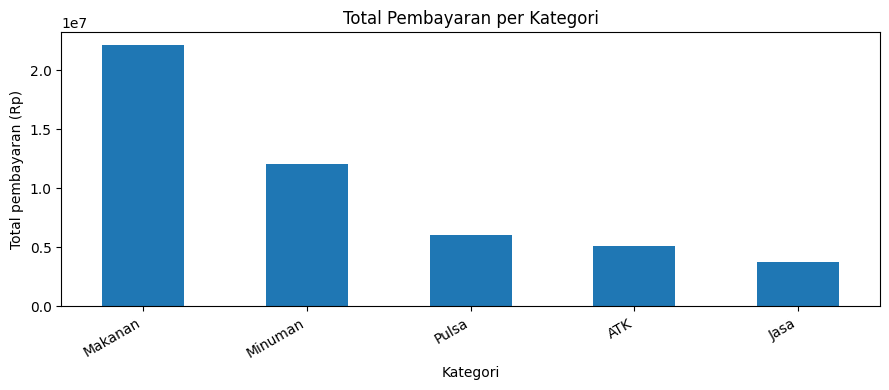

In [9]:
print("Ringkasan numerik:")
display(data_bersih[[
    "total_bayar", "jumlah", "harga_satuan", "diskon_persen",
    "saldo_simpanan", "rating_layanan", "berat_kg"
]].describe().T)

print("Total pembayaran per kategori:")
total_kategori = data_bersih.groupby("kategori", observed=True)["total_bayar"].sum().sort_values(ascending=False)
display(total_kategori.to_frame("total_bayar"))
ax = total_kategori.plot(kind="bar", figsize=(9,4), title="Total Pembayaran per Kategori")
ax.set_xlabel("Kategori"); ax.set_ylabel("Total pembayaran (Rp)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

Total pembayaran per bulan:


,total_bayar
bulan,
2025-08,13543925
2025-09,12243925
2025-10,12124875
2025-11,11232100


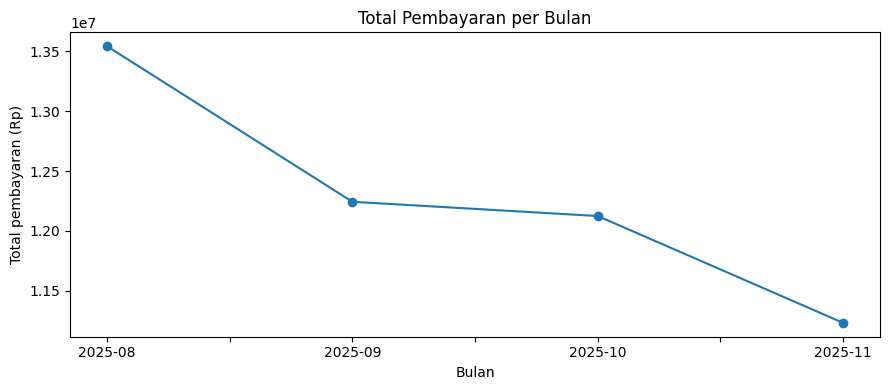

Metode pembayaran:


,jumlah_transaksi
metode_bayar,
Tunai,550
QRIS,465
Saldo Koperasi,279
Transfer,171
<NA>,28


In [10]:
print("Total pembayaran per bulan:")
total_bulan = data_bersih.groupby("bulan")["total_bayar"].sum().sort_index()
display(total_bulan.to_frame("total_bayar"))
ax = total_bulan.plot(kind="line", marker="o", figsize=(9,4), title="Total Pembayaran per Bulan")
ax.set_xlabel("Bulan"); ax.set_ylabel("Total pembayaran (Rp)")
plt.tight_layout(); plt.show()

print("Metode pembayaran:")
display(data_bersih["metode_bayar"].value_counts(dropna=False).to_frame("jumlah_transaksi"))

Rating layanan:


,jumlah
rating_layanan,
2.00,18
3.00,261
4.00,668
5.00,500
NaN,46


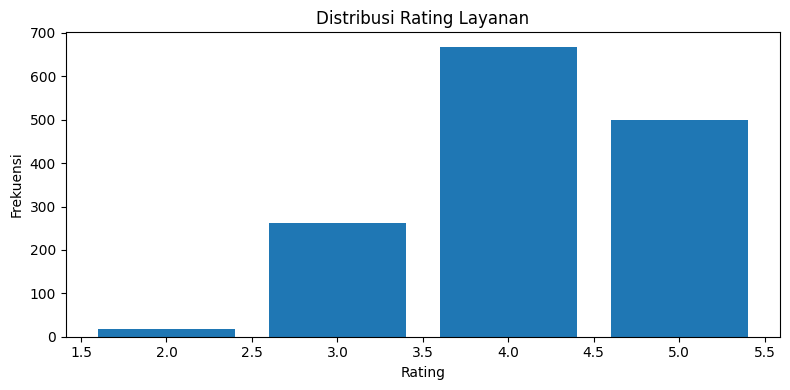

In [11]:
print("Rating layanan:")
display(data_bersih["rating_layanan"].value_counts(dropna=False).sort_index().to_frame("jumlah"))
ax = data_bersih["rating_layanan"].dropna().plot(
    kind="hist", bins=np.arange(1.5, 6.5, 1), rwidth=0.8,
    figsize=(8,4), title="Distribusi Rating Layanan"
)
ax.set_xlabel("Rating"); ax.set_ylabel("Frekuensi")
plt.tight_layout(); plt.show()

## 9. Tidy data: pivot, melt, dan merge

### 9.1 Pivot — ringkasan bulanan per kategori

Bentuk lebar memudahkan pembacaan total per bulan dan kategori.

In [12]:
tabel_lebar = data_bersih.pivot_table(
    index="bulan", columns="kategori", values="total_bayar",
    aggfunc="sum", observed=True
).fillna(0).round(0)
display(tabel_lebar)

kategori,ATK,Jasa,Makanan,Minuman,Pulsa
bulan,,,,,
2025-08,1498800,901450,5904300,3410675,1828700
2025-09,1251250,824200,5461800,3289175,1417500
2025-10,1337150,1299400,5087800,2817275,1583250
2025-11,1005100,753950,5648750,2571100,1253200


### 9.2 Melt — mengubah kembali menjadi bentuk panjang

Bentuk panjang memudahkan visualisasi dan analisis lanjutan karena kategori berada pada satu kolom.

In [13]:
tabel_panjang = (
    tabel_lebar.reset_index()
    .melt(id_vars="bulan", var_name="kategori", value_name="total_bayar")
)
print("Dimensi bentuk panjang:", tabel_panjang.shape)
display(tabel_panjang.head(10))

Dimensi bentuk panjang: (20, 3)


,bulan,kategori,total_bayar
0,2025-08,ATK,1498800
1,2025-09,ATK,1251250
2,2025-10,ATK,1337150
3,2025-11,ATK,1005100
4,2025-08,Jasa,901450
5,2025-09,Jasa,824200
6,2025-10,Jasa,1299400
7,2025-11,Jasa,753950
8,2025-08,Makanan,5904300
9,2025-09,Makanan,5461800


### 9.3 Merge — profil agregat anggota

Tabel agregat per anggota digabungkan kembali ke transaksi. `validate='many_to_one'` memastikan satu ID anggota hanya muncul satu kali pada tabel profil.

In [14]:
profil_anggota = (
    data_bersih.groupby("id_anggota", dropna=False)
    .agg(
        jumlah_transaksi=("id_transaksi", "count"),
        total_belanja=("total_bayar", "sum")
    ).reset_index()
)
gabung = data_bersih.merge(
    profil_anggota, on="id_anggota", how="left", validate="many_to_one"
)
print("Baris sebelum merge:", len(data_bersih))
print("Baris sesudah merge:", len(gabung))
display(profil_anggota.head())

Baris sebelum merge: 1493
Baris sesudah merge: 1493


,id_anggota,jumlah_transaksi,total_belanja
0,AGT1001,6,190000
1,AGT1002,8,258600
2,AGT1003,5,108000
3,AGT1004,6,231400
4,AGT1005,4,81500


## 10. Perbandingan sebelum dan sesudah

Perbandingan ini membantu menjelaskan dampak pembersihan. Nilai kosong dapat bertambah karena placeholder dan nilai mustahil diubah menjadi `NaN`; hal tersebut bukan berarti data mentah berubah.

In [15]:
perbandingan = pd.DataFrame({
    "sebelum": [
        len(mentah), len(mentah.columns),
        int(mentah.isna().sum().sum()),
        int(mentah.duplicated().sum()),
        int(mentah["id_transaksi"].nunique(dropna=True))
    ],
    "sesudah": [
        len(data_bersih), len(data_bersih.columns),
        int(data_bersih.isna().sum().sum()),
        int(data_bersih.duplicated().sum()),
        int(data_bersih["id_transaksi"].nunique(dropna=True))
    ]
}, index=["Jumlah baris", "Jumlah kolom", "Total sel kosong",
          "Duplikat baris penuh", "ID transaksi unik"])
display(perbandingan)

,sebelum,sesudah
Jumlah baris,1493,1493
Jumlah kolom,26,26
Total sel kosong,1721,1721
Duplikat baris penuh,0,0
ID transaksi unik,1493,1493


In [16]:
# Perbandingan kelengkapan pada kolom yang sama-sama ada di kedua versi.
kolom_bersama = [c for c in mentah.columns if c in data_bersih.columns]
banding_kosong = pd.DataFrame({
    "kosong_sebelum": mentah[kolom_bersama].isna().sum(),
    "kosong_sesudah": data_bersih[kolom_bersama].isna().sum()
})
banding_kosong["perubahan"] = banding_kosong["kosong_sesudah"] - banding_kosong["kosong_sebelum"]
display(banding_kosong.sort_values("perubahan", ascending=False))

,kosong_sebelum,kosong_sesudah,perubahan
id_transaksi,0,0,0
tanggal_transaksi,0,0,0
id_anggota,0,0,0
nama_produk,0,0,0
kategori,0,0,0
satuan,0,0,0
jumlah,29,29,0
harga_satuan,0,0,0
diskon_persen,9,9,0
total_bayar,0,0,0


## 11. Uji reproduktibilitas

Pipeline dijalankan dua kali pada data mentah yang sama. Hasil seharusnya identik. Pemeriksaan ini penting agar output tidak bergantung pada urutan eksekusi sel.

In [17]:
hasil_uji_1, log_uji_1, gagal_1 = bersihkan(mentah)
hasil_uji_2, log_uji_2, gagal_2 = bersihkan(mentah)

pd.testing.assert_frame_equal(
    hasil_uji_1.reset_index(drop=True),
    hasil_uji_2.reset_index(drop=True),
    check_dtype=False
)
pd.testing.assert_frame_equal(log_uji_1, log_uji_2)
print("LULUS: hasil pipeline dan cleaning log identik pada dua eksekusi.")

LULUS: hasil pipeline dan cleaning log identik pada dua eksekusi.


## 12. Ekspor dataset, cleaning log, dan laporan

Notebook menyimpan:
- `data/processed/transaksi_koperasi_2025_bersih.csv`
- `cleaning_log.md`
- `reports/laporan_kualitas_data_koperasi_2025.pdf`

PDF dibuat dengan ReportLab. Jika pustaka belum tersedia di runtime Colab, sel akan memasangnya terlebih dahulu.

In [18]:
from pathlib import Path
import subprocess, sys

Path("data/processed").mkdir(parents=True, exist_ok=True)
Path("reports").mkdir(parents=True, exist_ok=True)

# Ekspor dataset hasil olahan.
file_csv_hasil = "data/processed/transaksi_koperasi_2025_bersih.csv"
data_bersih.to_csv(file_csv_hasil, index=False)

# Ekspor cleaning log Markdown.
baris_log = [
    "# Cleaning Log",
    "",
    f"Dataset sumber: {NAMA_FILE}  ",
    f"Baris mentah: {len(mentah)} → baris hasil: {len(data_bersih)}  ",
    "",
    "| # | Langkah | Baris terdampak | Alasan |",
    "|---:|---|---:|---|"
]
for i, r in log_df.reset_index(drop=True).iterrows():
    alasan = str(r["Alasan"]).replace("|", "\\|")
    baris_log.append(
        f"| {i+1} | {r['Langkah']} | {r['Baris terdampak']} | {alasan} |"
    )
baris_log += [
    "",
    "## Keputusan manual yang perlu diverifikasi",
    "",
    "- `Alat Tulis` disatukan ke `ATK`; konfirmasi bahwa keduanya kategori yang sama.",
    "- `Minumam` dianggap salah ketik dari `Minuman`.",
    "- ID transaksi diasumsikan unik; untuk ID berulang, baris dengan catatan kasir terisi diprioritaskan.",
    "- `saldo_simpanan` tidak diimputasi karena pola kehilangan diduga MNAR.",
    "- Berat pada kategori jasa/pulsa ditandai tidak berlaku, bukan diisi.",
    "",
    "## Keterbatasan",
    "",
    "- Akurasi nominal belum diverifikasi terhadap bukti transaksi asli.",
    "- Ketidaksesuaian total pembayaran ditandai, bukan dikoreksi.",
    "- Aturan bisnis kategori dan ID perlu konfirmasi pengelola koperasi.",
    ""
]
Path("cleaning_log.md").write_text("\n".join(baris_log), encoding="utf-8")

print("CSV:", file_csv_hasil)
print("Cleaning log: cleaning_log.md")
display(log_df)

CSV: data/processed/transaksi_koperasi_2025_bersih.csv
Cleaning log: cleaning_log.md


,Langkah,Baris terdampak,Alasan
0,Konversi total_bayar ke angka,0,"Menghapus simbol ""Rp"" dan titik pemisah ribuan..."
1,Konversi tanggal berdasarkan pola format,1493,Tanggal ISO dan DD/MM/YYYY diparse terpisah ag...
2,Buang spasi awal dan akhir kolom teks,0,Spasi tersembunyi dapat membuat kategori atau ...
3,Placeholder teks menjadi kosong,0,Placeholder bukan observasi bermakna; menjadik...
4,Placeholder -999 pada rating menjadi kosong,0,-999 berada di luar skala rating layanan dan a...
5,Seragamkan kategori,0,Kapitalisasi dinormalkan; sinonim/salah ketik ...
6,Hapus duplikat persis,0,Seluruh kolom identik setelah normalisasi; sat...
7,Satukan duplikat menurut id_transaksi,0,Satu ID diasumsikan mewakili satu transaksi; b...
8,Buang baris tanpa id_transaksi,0,"Tanpa kunci transaksi, baris tidak dapat ditel..."
9,jumlah <= 0 menjadi kosong,0,Belum dapat dipastikan apakah retur atau salah...


### 12.1 Membuat laporan PDF

Laporan ini mengambil angka langsung dari hasil eksekusi notebook. Teks interpretasi harus ditinjau kembali setelah hasil berjalan, terutama bagian asumsi kategori dan aturan ID.

In [19]:
try:
    import reportlab
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "reportlab"])

from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, PageBreak
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import cm

pdf_path = "reports/laporan_kualitas_data_koperasi_2025.pdf"
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name="JudulTengah", parent=styles["Title"], alignment=1, fontSize=17, leading=22))
styles.add(ParagraphStyle(name="IsiKecil", parent=styles["BodyText"], fontSize=8.5, leading=12))
story = [
    Paragraph("LAPORAN KUALITAS DATA", styles["JudulTengah"]),
    Paragraph("Transaksi Koperasi 2025 — Exploratory Data Analysis (KMTI21133)", styles["Heading2"]),
    Spacer(1, 10),
    Paragraph(
        f"Dataset terdiri dari {len(mentah):,} baris dan {len(mentah.columns)} kolom sebelum pembersihan. "
        f"Setelah pipeline dijalankan, tersisa {len(data_bersih):,} baris dengan "
        f"{len(data_bersih.columns)} kolom termasuk indikator dan kolom turunan.",
        styles["BodyText"]
    ),
    Spacer(1, 8),
    Paragraph("1. Ringkasan temuan", styles["Heading2"]),
    Paragraph(
        f"Pembersihan mengubah format pembayaran menjadi numerik, memisahkan parsing tanggal ISO dan "
        f"DD/MM/YYYY, merapikan teks, menormalkan placeholder, menyeragamkan kategori, dan menangani "
        f"duplikasi. Terdapat {int(data_bersih['total_mencurigakan'].sum())} transaksi yang ditandai "
        f"memiliki selisih antara total tercatat dan estimasi hitungan.",
        styles["BodyText"]
    ),
    Spacer(1, 8),
    Paragraph("2. Ukuran dan cakupan", styles["Heading2"]),
]
summary_table = [
    ["Ukuran", "Sebelum", "Sesudah"],
    ["Jumlah baris", f"{len(mentah):,}", f"{len(data_bersih):,}"],
    ["Jumlah kolom", f"{len(mentah.columns)}", f"{len(data_bersih.columns)}"],
    ["Sel kosong", f"{int(mentah.isna().sum().sum()):,}", f"{int(data_bersih.isna().sum().sum()):,}"],
    ["Duplikat penuh", f"{int(mentah.duplicated().sum()):,}", f"{int(data_bersih.duplicated().sum()):,}"],
    ["ID transaksi unik", f"{int(mentah['id_transaksi'].nunique()):,}", f"{int(data_bersih['id_transaksi'].nunique()):,}"],
]
tbl = Table(summary_table, colWidths=[6*cm, 4*cm, 4*cm])
tbl.setStyle(TableStyle([
    ("BACKGROUND",(0,0),(-1,0),colors.HexColor("#243B53")),
    ("TEXTCOLOR",(0,0),(-1,0),colors.white),
    ("GRID",(0,0),(-1,-1),0.4,colors.grey),
    ("ROWBACKGROUNDS",(0,1),(-1,-1),[colors.white,colors.HexColor("#F2F5F8")]),
    ("PADDING",(0,0),(-1,-1),6),
]))
story += [tbl, Spacer(1, 10), Paragraph("3. Temuan kualitas dan keputusan", styles["Heading2"])]
log_table = [["Langkah", "Baris", "Alasan ringkas"]]
for _, r in log_df.iterrows():
    log_table.append([str(r["Langkah"]), str(r["Baris terdampak"]), str(r["Alasan"])])
tbl2 = Table(log_table, colWidths=[5.2*cm, 1.5*cm, 8.3*cm], repeatRows=1)
tbl2.setStyle(TableStyle([
    ("BACKGROUND",(0,0),(-1,0),colors.HexColor("#243B53")),
    ("TEXTCOLOR",(0,0),(-1,0),colors.white),
    ("GRID",(0,0),(-1,-1),0.35,colors.grey),
    ("FONTSIZE",(0,0),(-1,-1),7),
    ("VALIGN",(0,0),(-1,-1),"TOP"),
    ("PADDING",(0,0),(-1,-1),4),
]))
story += [tbl2, PageBreak(), Paragraph("4. Profil numerik setelah pembersihan", styles["Heading2"])]
desc = data_bersih[["total_bayar","jumlah","diskon_persen","saldo_simpanan","rating_layanan"]].describe().round(2)
desc_data = [["Statistik"] + list(desc.columns)]
for idx, row in desc.iterrows():
    desc_data.append([str(idx)] + [f"{v:,.2f}" for v in row.values])
tbl3 = Table(desc_data, repeatRows=1)
tbl3.setStyle(TableStyle([
    ("BACKGROUND",(0,0),(-1,0),colors.HexColor("#243B53")),
    ("TEXTCOLOR",(0,0),(-1,0),colors.white),
    ("GRID",(0,0),(-1,-1),0.35,colors.grey),
    ("FONTSIZE",(0,0),(-1,-1),7),
    ("PADDING",(0,0),(-1,-1),5),
]))
story += [tbl3, Spacer(1, 10), Paragraph("5. Peta keputusan manual", styles["Heading2"])]
for line in [
    "• Alat Tulis dipetakan ke ATK berdasarkan asumsi sinonim; perlu konfirmasi pengelola.",
    "• Minumam dipetakan ke Minuman sebagai koreksi salah ketik yang tampak jelas.",
    "• Untuk ID transaksi berulang, satu baris dipilih dengan memprioritaskan catatan kasir terisi; asumsi satu ID untuk satu transaksi harus dikonfirmasi.",
    "• Jumlah nol/negatif dan diskon di luar 0–100 dikosongkan, bukan ditebak.",
    "• Selisih total pembayaran ditandai dan tidak ditimpa.",
    "• Saldo simpanan yang kosong tidak diimputasi; dugaan MNAR belum dapat dibuktikan tanpa informasi mekanisme data hilang.",
    "• Berat pada pulsa/jasa dianggap tidak berlaku dan dicatat melalui indikator berlaku_berat."
]:
    story.append(Paragraph(line, styles["IsiKecil"]))
    story.append(Spacer(1, 4))
story += [
    Spacer(1, 8),
    Paragraph("6. Keterbatasan", styles["Heading2"]),
    Paragraph(
        "Dataset tidak disertai bukti transaksi, kamus data, atau aturan bisnis resmi. Karena itu akurasi "
        "total pembayaran, arti ID berulang, pemetaan kategori, dan mekanisme nilai kosong belum dapat "
        "diverifikasi sepenuhnya. Nilai yang mencurigakan hanya ditandai. Hasil deskriptif tidak membuktikan "
        "hubungan sebab-akibat.",
        styles["BodyText"]
    ),
    Spacer(1, 8),
    Paragraph("7. Kesimpulan", styles["Heading2"]),
    Paragraph(
        f"Dataset dapat digunakan untuk eksplorasi awal setelah normalisasi dan penanganan duplikasi. "
        f"Namun, {int(data_bersih['total_mencurigakan'].sum())} transaksi masih memerlukan pemeriksaan "
        f"nominal, dan keputusan kategori/ID perlu dikonfirmasi. Sebelum analisis operasional atau keputusan "
        f"keuangan, cocokkan hasil dengan bukti transaksi serta aturan koperasi.",
        styles["BodyText"]
    ),
    Spacer(1, 8),
    Paragraph("Lampiran: cleaning log terpisah tersedia sebagai cleaning_log.md.", styles["Italic"])
]
doc = SimpleDocTemplate(pdf_path, pagesize=A4, rightMargin=1.6*cm, leftMargin=1.6*cm, topMargin=1.5*cm, bottomMargin=1.5*cm)
doc.build(story)
print("PDF tersimpan:", pdf_path)

PDF tersimpan: reports/laporan_kualitas_data_koperasi_2025.pdf


### 12.2 Unduh semua hasil dari Google Colab

Jalankan sel berikut untuk mengemas CSV hasil, cleaning log, dan laporan PDF menjadi satu ZIP.

In [20]:
import zipfile
paket = "hasil_pembersihan_koperasi_2025.zip"
with zipfile.ZipFile(paket, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(file_csv_hasil)
    z.write("cleaning_log.md")
    z.write(pdf_path)
print("Paket siap:", paket)

try:
    from google.colab import files
    files.download(paket)
except ImportError:
    print("Di luar Google Colab, ambil file dari direktori kerja:", paket)

Paket siap: hasil_pembersihan_koperasi_2025.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Daftar periksa sebelum pengumpulan

- [ ] Jalankan seluruh notebook dari awal sampai akhir.
- [ ] Pastikan file mentah tidak tertimpa.
- [ ] Konfirmasi pemetaan `Alat Tulis → ATK` dan `Minumam → Minuman`.
- [ ] Konfirmasi apakah `id_transaksi` wajib unik dan aturan memilih catatan yang terisi.
- [ ] Tinjau daftar transaksi yang ditandai `total_mencurigakan`.
- [ ] Pastikan alasan pada cleaning log sesuai dengan keputusan yang benar-benar digunakan.
- [ ] Baca laporan PDF dan sesuaikan interpretasi dengan hasil eksekusi.
- [ ] Simpan CSV hasil, cleaning log, dan PDF laporan bersama notebook.

**Kesimpulan akhir harus ditulis berdasarkan hasil aktual dan aturan bisnis yang sudah dikonfirmasi.**